# Relatório 02 — Divisão Treino/Teste e Análise Exploratória dos Dados

**Projeto:** Previsão de evasão de clientes (churn) em 60 dias

**Etapa:** protocolo experimental e análise exploratória (Aula 3 — PBL / CIn-UFPE)

**Entrada:** `data/processed/base_limpa.csv`

**Saída:** `data/processed/base_particionada.csv`

---

### Resumo

Esta etapa dá o passo que separa a preparação dos dados da modelagem propriamente dita. Ele começa pela ***divisão da base em treino (70%) e teste (30%)***, feita de forma estratificada e reprodutível, e explica por que essa divisão precisa acontecer **antes** de qualquer análise que aprenda algo dos dados. A partir daí, todo o estudo é feito exclusivamente no conjunto de
treino, e o teste fica guardado como uma amostra "nunca vista", que só será usada para avaliar o modelo final.

Com o treino isolado, conduzimos uma ***análise exploratória (EDA)*** em camadas: primeiro o retrato de cada variável sozinha (estatística descritiva, frequências, ausências e formato das distribuições); depois a relação de cada variável com o churn (boxplots, taxas por categoria e por faixa); e, por fim, a relação das variáveis entre si (correlações) e a busca por valores atípicos. Cada achado é interpretado e convertido em uma decisão ou recomendação para o notebook 03.

Os principais resultados são: a divisão preservou exatamente a taxa de churn de 35,4% nos dois conjuntos; contrato mensal, poucos meses de casa, muitos chamados e atrasos de pagamento são os sinais mais fortes de evasão; a forma de pagamento praticamente não diferencia os clientes; e `fibra_optica` e `mensalidade_rs` são fortemente correlacionadas entre si (r = 0,85), carregando em boa parte a mesma informação.

## 1. Introdução

### 1.1 Onde estamos no projeto

O Relatório 01 entregou uma base limpa: 4.976 clientes, uma linha por cliente, categorias padronizadas, valores sentinela convertidos em ausentes e o rótulo `churn` construído a partir da data de corte. Foram aplicadas ali apenas correções **determinísticas**, que não dependem de estatísticas da base. Com isso, ficaram pendentes as transformações que **aprendem** com os dados como imputação, escalonamento e codificação, e, antes delas, uma pergunta metodológica central: com quais dados o modelo vai aprender, e com quais ele será avaliado?

### 1.2 Generalização: o que realmente queremos medir

Um modelo de aprendizagem de máquina não é útil por acertar os clientes que já conhece, e sim por acertar clientes **novos**, que ele nunca viu, os clientes da próxima fotografia, quando o modelo estiver em produção. Essa capacidade se chama **generalização**. O problema é que, no momento do desenvolvimento, não temos esses clientes futuros. A solução clássica é simular essa situação: separamos uma parte dos dados que conhecemos e a escondemos do processo de aprendizagem. Essa parte, o ***conjunto de teste***, faz o papel do futuro.

Se o teste participar de qualquer decisão, inclusive decisões aparentemente inocentes, como escolher qual variável transformar depois de olhar um gráfico, ele deixa de ser "futuro" e passa a ser parte do treino. A avaliação final se torna otimista e enganosa. Esse fenômeno é chamado de **vazamento de dados** (*data leakage*) ou, quando ocorre pelo olhar do analista, de **bisbilhotagem de dados** (*data snooping*).

### 1.3 Por que a EDA é feita só no treino

A análise exploratória pode parecer neutra, já que "só olha" os dados. Mas ela orienta escolhas: qual estatística usar para imputar, se uma variável deve ser transformada, quais variáveis manter, quais faixas parecem relevantes. Se essas escolhas fossem feitas olhando também o teste, o teste estaria influenciando o modelo de forma indireta. Por isso, a ordem deste relatório é rígida: **primeiro dividimos, depois exploramos**, e a exploração usa apenas o treino.

A Aula 3 vai além e recomenda que, em rigor, a separação do teste aconteça no início de tudo, antes inclusive do controle de qualidade. No nosso projeto, o Relatório 01 aplicou apenas regras fixas (de-para, faixas válidas, remoção de duplicatas exatas, construção do rótulo), que seriam aplicadas do mesmo jeito a um cliente isolado em produção e não usam nenhuma estatística calculada sobre a base. Por isso, realizá-las antes da divisão não contamina o teste.

### 1.4 Roteiro do relatório

A **Seção 2** prepara o ambiente e valida a base de entrada. A **Seção 3** explica e executa a divisão estratificada e confere que ela preservou a proporção de churn. A **Seção 4** faz o retrato univariado do treino: estatísticas descritivas, frequências das categorias e dados ausentes. A **Seção 5** estuda a relação de cada variável com o churn, por meio de
distribuições, boxplots e taxas de evasão por grupo. A **Seção 6** examina as relações entre as variáveis (correlação) e os valores atípicos. A **Seção 7** exporta a base particionada, e a **Seção 8** reúne os achados e as recomendações para o notebook 03.

## 2. Ambiente e validação da base de entrada

A primeira célula importa as bibliotecas e localiza a raiz do projeto, onde está o `config.py`. Ela funciona em três situações: rodando a partir da raiz, rodando a partir da pasta `notebooks/` ou rodando no Colab (quando clona o repositório). Do `config.py` vêm, além dos caminhos e nomes de colunas, dois parâmetros do experimento: `TAMANHO_TESTE = 0.30` e `RANDOM_STATE = 42`. Mantê-los centralizados garante que todos os integrantes do grupo e todos os
notebooks usem exatamente a mesma partição.

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

REPO_URL = "https://github.com/Gagdm/previsao_de_evasao_de_clientes.git"

# Descobre onde está a raiz do projeto (a pasta que contém config.py):
cwd = Path.cwd()
if (cwd / "config.py").exists():             # executando a partir da raiz
    raiz = cwd
elif (cwd.parent / "config.py").exists():    # executando a partir de notebooks/
    raiz = cwd.parent
else:                                        # executando no Colab: clona o repositório se preciso
    raiz = Path("/content/previsao_de_evasao_de_clientes")
    if not raiz.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(raiz)], check=True)

# Coloca a raiz no caminho de busca do Python para que "from config import ..." funcione.
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# Constantes compartilhadas entre os notebooks.
from config import (
    ALVO, BASE_LIMPA, BASE_PARTICIONADA, BINARIAS, CATEGORICAS,
    ID, NUMERICAS, RANDOM_STATE, TAMANHO_TESTE,
)

# Estilo visual padrão dos gráficos e exibição de todas as colunas nas tabelas.
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

print(f"Repositório: {raiz}")
print(f"Arquivo de entrada: {BASE_LIMPA}")
print(f"Partição: {int((1-TAMANHO_TESTE)*100)}% treino / {int(TAMANHO_TESTE*100)}% teste; seed={RANDOM_STATE}")

Repositório: /content/previsao_de_evasao_de_clientes
Arquivo de entrada: /content/previsao_de_evasao_de_clientes/data/processed/base_limpa.csv
Partição: 70% treino / 30% teste; seed=42


Antes de usar a base, verificamos se ela cumpre o **contrato de dados** herdado do Relatório 01. Esse cuidado é importante porque este notebook depende de um arquivo gerado por outro: se o notebook 01 mudar ou não tiver sido executado, queremos que o erro apareça aqui, de forma clara, e não como um resultado estranho dez células depois. As verificações seguem as regras de
bloqueio de pipeline da Aula 2: todas as colunas esperadas presentes; identificador único e sem vazios; alvo binário (0/1) e sem vazios; e as duas classes presentes, condição necessária para a divisão estratificada.

In [2]:
# Interrompe com mensagem clara se o arquivo do Relatório 01 não existir.
if not BASE_LIMPA.is_file():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {BASE_LIMPA}. Execute antes o notebook 01."
    )

df = pd.read_csv(BASE_LIMPA)

# Regra 1 - esquema: todas as colunas previstas no config precisam existir.
colunas_esperadas = [ID, ALVO] + NUMERICAS + CATEGORICAS + BINARIAS
faltantes = sorted(set(colunas_esperadas) - set(df.columns))   # diferença de conjuntos
if faltantes:
    raise ValueError(f"Colunas necessárias não encontradas: {faltantes}")
# Regra 2 - chave primária: id_cliente sem vazios e sem repetições.
if df[ID].isna().any() or df[ID].duplicated().any():
    raise ValueError("A base precisa ter identificadores de cliente únicos e válidos.")
# Regra 3 - alvo: apenas 0 e 1, sem vazios.
if df[ALVO].isna().any() or not set(df[ALVO].unique()).issubset({0, 1}):
    raise ValueError("A variável churn deve ser binária (0/1) e não pode ter nulos.")
# Regra 4 - as duas classes precisam existir para que a estratificação seja possível.
if df[ALVO].nunique() != 2:
    raise ValueError("As duas classes de churn devem estar presentes para a estratificação.")

print(f"Clientes: {len(df):,} | Colunas: {df.shape[1]}")
display(df.head())
print("Tipos das variáveis:")
# dtypes mostra como cada coluna foi lida: int/float = numérica, object = texto/categoria.
display(df.dtypes.rename("tipo").to_frame())

Clientes: 4,976 | Colunas: 10


,id_cliente,tempo_cliente_meses,mensalidade_rs,chamados_totais,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,churn
0,C0001,29,67.96,2,0.0,Bienal,Boleto,0,0,0
1,C0002,19,65.95,0,0.0,Mensal,Cartão,0,0,0
2,C0003,18,100.88,1,1.0,Anual,Boleto,1,1,0
3,C0004,18,94.80,2,2.0,Mensal,Cartão,0,1,0
4,C0005,55,53.68,1,2.0,Anual,Pix,0,0,0


Tipos das variáveis:


,tipo
id_cliente,object
tempo_cliente_meses,int64
mensalidade_rs,float64
chamados_totais,int64
atrasos_6m,float64
tipo_contrato,object
forma_pagamento,object
fibra_optica,int64
debito_automatico,int64
churn,int64


A base chega íntegra: **4.976 clientes e 10 colunas**, exatamente o que o Relatório 01 exportou. Os tipos estão coerentes com o papel de cada variável: as quatro numéricas como `int` ou `float` (`mensalidade_rs` e `atrasos_6m` são `float` porque contêm ausentes, que o pandas representa como `NaN`), as duas categóricas como texto (`object`) e as binárias e o alvo como inteiros 0/1.

## 3. Divisão treino/teste

### 3.1 Fundamentos

A técnica usada é a **validação por retenção** (*holdout*): a base é dividida uma única vez em duas partes disjuntas. O **treino** (70%, cerca de 3.480 clientes) será usado para tudo o que envolve aprender, explorar, escolher transformações, ajustar imputadores e escaladores (`.fit`) e treinar o classificador. O **teste** (30%, cerca de 1.490 clientes) ficará intocado
até a avaliação final, quando receberá apenas `.transform` e `.predict` com as regras aprendidas no treino.

A proporção 70/30 é um equilíbrio: o treino precisa ser grande o bastante para que o modelo aprenda padrões estáveis, e o teste precisa ser grande o bastante para que as métricas finais tenham pouca variação aleatória. Com cerca de 530 clientes de churn no teste, uma métrica como o *recall* terá margem de erro de poucos pontos percentuais. A Aula 3 também apresenta a
**validação cruzada k-fold**, que repete a divisão várias vezes; ela será útil para escolher hiperparâmetros **dentro** do treino, mas o teste continua separado para a avaliação final.

Dois parâmetros da divisão merecem explicação:

- ***Estratificação (`stratify`):***
uma divisão puramente aleatória poderia, por acaso, colocar
proporções diferentes de churn no treino e no teste. Isso distorceria tanto o aprendizado quanto a avaliação, porque métricas como precisão dependem
da prevalência da classe positiva. Ao estratificar pelo alvo, a função sorteia separadamente dentro de cada classe, garantindo que os dois conjuntos tenham a mesma taxa de churn da base completa. A estratificação é especialmente importante quando a classe de interesse é minoritária, como aqui.

- ***Semente aleatória (`random_state`):*** O sorteio é feito por um gerador pseudoaleatório. Fixar a semente em 42 faz com que o sorteio seja sempre o mesmo, em qualquer computador e a cada execução. Isso garante **reprodutibilidade**: todos os resultados do grupo se referem à mesma
partição e podem ser auditados.

### 3.2 Execução

O código divide a base, marca cada linha com uma nova coluna `split` (`treino` ou `teste`) e junta tudo novamente em um único arquivo. Guardar a partição como uma coluna, em vez de salvar dois arquivos, deixa explícito qual cliente pertence a qual conjunto e garante que o notebook 03 use exatamente a mesma divisão. Em seguida, quatro verificações automáticas confirmam que nenhuma linha foi perdida ou duplicada e que **nenhum cliente aparece nos dois conjuntos**.

In [3]:
COLUNA_PARTICAO = "split"
# Proteção: se a base de entrada já tivesse uma coluna "split", ela seria sobrescrita.
if COLUNA_PARTICAO in df.columns:
    raise ValueError(f"A coluna {COLUNA_PARTICAO!r} já existe na base de entrada.")

# Divisão holdout estratificada:
#   test_size=0.30      -> 30% das linhas vão para o teste
#   random_state=42     -> sorteio sempre igual (reprodutível)
#   stratify=df[ALVO]   -> mesma proporção de churn nos dois conjuntos
treino, teste = train_test_split(
    df,
    test_size=TAMANHO_TESTE,
    random_state=RANDOM_STATE,
    stratify=df[ALVO],
)
# .copy() cria tabelas independentes, evitando avisos e alterações acidentais em df.
treino = treino.copy()
teste = teste.copy()
treino[COLUNA_PARTICAO] = "treino"
teste[COLUNA_PARTICAO] = "teste"

# Junta os dois conjuntos de volta em uma única tabela, ordenada por id_cliente.
# kind="stable" mantém a ordem relativa em caso de empate; reset_index renumera as linhas.
base_particionada = (
    pd.concat([treino, teste], ignore_index=True)
    .sort_values(ID, kind="stable")
    .reset_index(drop=True)
)

# Verificações automáticas da partição (interrompem a execução se algo estiver errado):
assert len(treino) + len(teste) == len(df)                 # nenhuma linha perdida ou criada
assert set(treino[ID]).isdisjoint(set(teste[ID]))          # nenhum cliente nos dois conjuntos
assert base_particionada[ID].is_unique                     # nenhum cliente duplicado
assert not base_particionada[COLUNA_PARTICAO].isna().any() # toda linha tem partição definida

print(f"Treino: {len(treino):,} linhas ({len(treino)/len(df):.1%})")
print(f"Teste:  {len(teste):,} linhas ({len(teste)/len(df):.1%})")

# Tabela-resumo: tamanho e taxa de churn (média do alvo 0/1) em cada conjunto.
display(
    pd.DataFrame({
        "quantidade": [len(df), len(treino), len(teste)],
        "taxa_churn": [df[ALVO].mean(), treino[ALVO].mean(), teste[ALVO].mean()],
    }, index=["Total", "Treino", "Teste"]).style.format({"taxa_churn": "{:.2%}"})
)

Treino: 3,483 linhas (70.0%)
Teste:  1,493 linhas (30.0%)


,quantidade,taxa_churn
Total,4976,35.43%
Treino,3483,35.43%
Teste,1493,35.43%


### 3.3 Conferência visual da estratificação

O gráfico abaixo compara a composição das classes nos dois conjuntos. Se a estratificação funcionou, as barras de cada classe devem ter a mesma altura no treino e no teste.

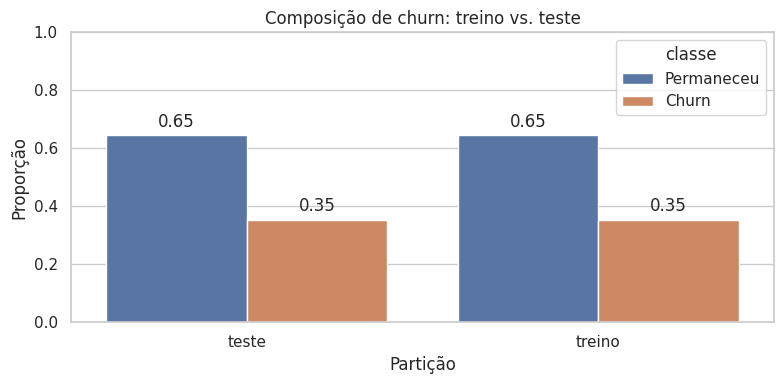

In [4]:
# Para cada partição, calcula a proporção de cada classe (normalize=True devolve proporções
# em vez de contagens). O resultado é uma tabela longa: partição | churn | proporção.
composicao = (
    base_particionada.groupby(COLUNA_PARTICAO)[ALVO]
    .value_counts(normalize=True)
    .rename("proporcao")
    .reset_index()
)
# Troca 0/1 por rótulos legíveis para a legenda.
composicao["classe"] = composicao[ALVO].map({0: "Permaneceu", 1: "Churn"})

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=composicao, x=COLUNA_PARTICAO, y="proporcao", hue="classe")
ax.set(ylabel="Proporção", xlabel="Partição", title="Composição de churn: treino vs. teste", ylim=(0, 1))
# Escreve o valor de cada barra acima dela.
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

A divisão resultou em **3.483 clientes no treino (70,0%) e 1.493 no teste (30,0%)**, e a taxa de churn ficou em **35,43% nos dois conjuntos**, idêntica à da base completa até a segunda casa decimal. São 1.234 clientes de churn no treino e 529 no teste. A estratificação cumpriu seu papel: treino e teste são amostras representativas da mesma população.

**A partir deste ponto, toda a análise usa apenas o DataFrame `treino`.** O teste só volta a ser usado na avaliação final do modelo.

## 4. Retrato univariado do conjunto de treino

A análise exploratória começa olhando cada variável isoladamente. O objetivo é responder a perguntas básicas, mas indispensáveis: **qual é o valor típico de cada variável? Quanto ela varia? A distribuição é simétrica ou concentrada de um lado? Há categorias raras? Quantos dados faltam?**

### 4.1 Estatística descritiva das variáveis numéricas

O `describe()` resume cada variável numérica em oito números:

- **count**: quantos valores preenchidos existem (diferenças em relação ao total indicam ausentes);
- **mean** (média) e **50%** (mediana): duas medidas de valor típico. A média usa todos os valores e por isso é puxada por extremos; a mediana é o valor do meio e é **robusta** a eles.;
- **std** (desvio padrão): o quanto os valores se afastam, em média, da média;
- **min**, **25%**, **75%** e **max**: o mínimo, o primeiro quartil (25% dos clientes estão abaixo), o terceiro quartil (75% estão abaixo) e o máximo. A distância entre 25% e 75% é o **intervalo interquartil (IQR)**, a faixa que contém a metade central dos clientes.

Depois, as mesmas medidas são calculadas **separadamente para quem cancelou e para quem permaneceu**. Essa é a primeira pista de quais variáveis diferenciam as classes.

In [5]:
# describe() calcula as estatísticas por coluna; .T transpõe para ter uma variável por linha.
print("Estatísticas descritivas — variáveis numéricas:")
display(treino[NUMERICAS].describe().T.round(2))

# groupby(ALVO) separa os clientes em churn=0 e churn=1; agg calcula média, mediana e desvio
# padrão de cada variável numérica dentro de cada grupo.
print("\nResumo das variáveis numéricas por classe de churn:")
display(treino.groupby(ALVO)[NUMERICAS].agg(["mean", "median", "std"]).round(2))

Estatísticas descritivas — variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
tempo_cliente_meses,3483.0,24.82,15.50,2.0,13.00,21.00,33.00,72.00
mensalidade_rs,3389.0,83.42,18.30,49.9,67.14,86.04,98.42,136.42
chamados_totais,3483.0,1.71,1.44,0.0,1.00,1.00,2.50,10.00
atrasos_6m,3452.0,1.04,0.95,0.0,0.00,1.00,2.00,5.00



Resumo das variáveis numéricas por classe de churn:


tempo_cliente_meses               mensalidade_rs                \
                     mean median    std           mean median    std   
churn                                                                  
0                   27.82   24.0  16.39          81.43  81.76  18.43   
1                   19.36   17.0  11.95          87.07  90.61  17.49   

      chamados_totais              atrasos_6m               
                 mean median   std       mean median   std  
churn                                                       
0                1.42    1.0  1.27       0.88    1.0  0.88  
1                2.23    2.0  1.58       1.33    1.0  1.01

**Leitura das estatísticas gerais.** O tempo de casa vai de 2 a 72 meses, com mediana de 21 e média de 24,8: a média acima da mediana indica uma cauda de clientes muito antigos. A mensalidade é a variável mais "bem-comportada": média (R\$ 83,42) e mediana (R\$ 86,04) próximas, o que sugere uma distribuição aproximadamente simétrica entre R\$ 49,90 e R\$ 136,42. Os chamados têm mediana 1 e máximo 10, um formato típico de contagem de eventos, com muitos valores baixos e poucos altos. Os atrasos vão de 0 a 5, com mediana 1. A coluna `count` mostra que `mensalidade_rs` (3.389 de 3.483) e `atrasos_6m` (3.452) têm ausentes.

**Leitura por classe.** As quatro variáveis numéricas mostram diferenças claras entre quem cancelou e quem ficou, sempre na direção esperada pelo negócio:

- **Tempo de casa**: quem cancelou tem mediana de 17 meses, contra 24 de quem ficou. Clientes mais recentes cancelam mais.
- **Chamados**: mediana de 2 entre os que cancelaram contra 1 entre os que ficaram. Mais contato com o suporte indica mais problemas.
- **Atrasos**: média de 1,33 contra 0,88. Dificuldade de pagamento antecede a saída.
- **Mensalidade**: mediana de R\$ 90,61 contra R\$ 81,76. Clientes que pagam mais cancelam um pouco mais, possivelmente por sensibilidade a preço.

Essas diferenças de média e mediana são um indício, não uma prova; as seções seguintes examinam as distribuições inteiras.

### 4.2 Frequência das variáveis categóricas e binárias

Para variáveis categóricas, as perguntas são outras: quantas categorias existem, como os clientes se distribuem entre elas e se há categorias raras. Categorias com pouquíssimos clientes são problemáticas, porque qualquer estatística calculada sobre elas (como a taxa de churn) fica instável, e a codificação one-hot criaria colunas quase sempre iguais a zero. O parâmetro
`dropna=False` faz os ausentes aparecerem como uma linha própria (`NaN`).

In [6]:
for coluna in CATEGORICAS + BINARIAS:
    print(f"\nDistribuição — {coluna}:")
    frequencias = (
        treino[coluna]
        .value_counts(dropna=False)              # contagem por categoria, incluindo NaN
        .rename_axis(coluna)                     # nomeia o índice com o nome da coluna
        .reset_index(name="quantidade")          # transforma em tabela: categoria | quantidade
    )
    # Percentual de cada categoria em relação ao total do treino.
    frequencias["percentual"] = 100 * frequencias["quantidade"] / len(treino)
    display(frequencias.round(2))


Distribuição — tipo_contrato:


,tipo_contrato,quantidade,percentual
0,Mensal,1932,55.47
1,Anual,819,23.51
2,Bienal,715,20.53
3,NaN,17,0.49



Distribuição — forma_pagamento:


,forma_pagamento,quantidade,percentual
0,Boleto,1364,39.16
1,Cartão,1206,34.63
2,Pix,899,25.81
3,NaN,14,0.40



Distribuição — fibra_optica:


,fibra_optica,quantidade,percentual
0,1,1972,56.62
1,0,1511,43.38



Distribuição — debito_automatico:


,debito_automatico,quantidade,percentual
0,0,2116,60.75
1,1,1367,39.25


Não há categorias raras: a menor categoria (`Bienal`, com 20,5%) tem mais de 700 clientes. O contrato **mensal é predominante** (55,5% dos clientes), o que é relevante porque, como veremos, é também o contrato com maior evasão. As formas de pagamento estão razoavelmente distribuídas (Boleto 39,2%, Cartão 34,6%, Pix 25,8%). Entre as binárias, 56,6% dos clientes têm fibra óptica
e 39,3% usam débito automático. As categóricas têm poucos ausentes (17 em `tipo_contrato` e 14 em `forma_pagamento`, menos de 0,5% cada).

### 4.3 Dados ausentes no treino

O Relatório 01 deixou as ausências propositalmente sem preenchimento. Aqui medimos quantas caíram no treino, porque é sobre ele que o imputador será ajustado no notebook 03. Também repetimos, já no treino, o teste de mecanismo de ausência feito no Relatório 01: se a taxa de churn for diferente entre quem tem e quem não tem mensalidade, a ausência pode carregar informação (MNAR) e vale criar um indicador de ausência.

,quantidade,percentual
mensalidade_rs,94,2.70
atrasos_6m,31,0.89
tipo_contrato,17,0.49
forma_pagamento,14,0.40
id_cliente,0,0.00
tempo_cliente_meses,0,0.00
chamados_totais,0,0.00
fibra_optica,0,0.00
debito_automatico,0,0.00
churn,0,0.00


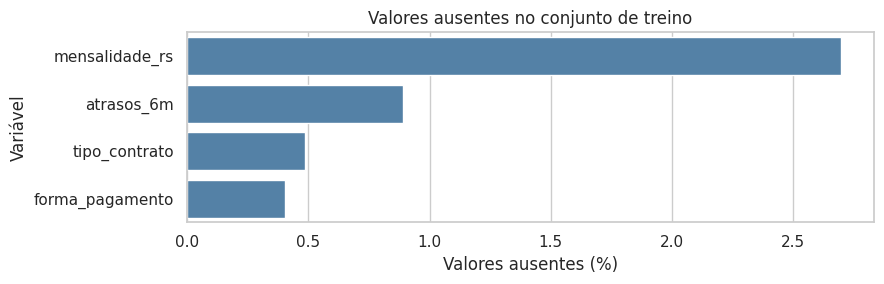

Taxa de churn com e sem mensalidade registrada (treino):


,n_clientes,taxa_churn
mensalidade_rs,,
com mensalidade,3389,35.29%
sem mensalidade,94,40.43%


In [7]:
# Contagem e percentual de ausentes por coluna, do maior para o menor.
ausentes = treino.isna().sum().rename("quantidade").to_frame()
ausentes["percentual"] = 100 * ausentes["quantidade"] / len(treino)
ausentes = ausentes.sort_values("quantidade", ascending=False)
display(ausentes.round(2))

# Gráfico apenas das colunas que têm alguma ausência.
com_ausentes = ausentes[ausentes["quantidade"] > 0]
if com_ausentes.empty:
    print("Não há campos ausentes no treino.")
else:
    plt.figure(figsize=(9, 3))
    sns.barplot(x=com_ausentes["percentual"], y=com_ausentes.index, color="steelblue")
    plt.xlabel("Valores ausentes (%)")
    plt.ylabel("Variável")
    plt.title("Valores ausentes no conjunto de treino")
    plt.tight_layout()
    plt.show()

# Teste de mecanismo: taxa de churn entre clientes com e sem mensalidade registrada.
print("Taxa de churn com e sem mensalidade registrada (treino):")
display(
    treino.groupby(treino["mensalidade_rs"].isna().map({False: "com mensalidade", True: "sem mensalidade"}))[ALVO]
    .agg(n_clientes="size", taxa_churn="mean")
    .style.format({"taxa_churn": "{:.2%}"})
)

As ausências são pequenas e concentradas em quatro colunas: `mensalidade_rs` (94 clientes, 2,7%), `atrasos_6m` (31, 0,9%), `tipo_contrato` (17, 0,5%) e `forma_pagamento` (14, 0,4%). Nenhuma passa do limite de alerta de 20% definido no contrato de dados da Aula 2, e todas são pequenas o bastante para uma **imputação simples** (mediana nas numéricas, moda nas categóricas) sem distorcer as distribuições. Excluir esses clientes seria uma alternativa pior: perderíamos cerca de 4% do treino e correríamos risco de viés caso a ausência não seja completamente aleatória.

O teste de mecanismo repete o padrão visto no Relatório 01: 40,4% de churn entre os clientes sem mensalidade contra 35,3% entre os demais. Com apenas 94 clientes no grupo sem mensalidade, essa diferença ainda está dentro da margem de variação aleatória (erro padrão de cerca de 5 pontos), mas a recomendação se mantém: **criar o indicador `mensalidade_ausente`** junto com a imputação,
para não descartar um possível sinal.

## 5. Relação das variáveis com o churn

Conhecido o retrato de cada variável, passamos à pergunta que interessa ao modelo: **quais variáveis ajudam a separar quem cancela de quem permanece?** Usamos três ferramentas complementares: histogramas por classe (formato completo das distribuições), boxplots (resumo comparativo de posição e dispersão) e taxas de churn por grupo (leitura direta em termos de
negócio).

Uma ressalva vale para toda esta seção: a EDA revela **associações**, não causas. Se clientes com muitos chamados cancelam mais, isso não prova que os chamados causam o cancelamento; ambos podem ser consequência de um terceiro fator, como a má qualidade do sinal na região do cliente. Para o modelo preditivo, uma associação estável já é útil; para decisões de negócio, ela é um ponto de partida para investigação.

### 5.1 Distribuições das variáveis numéricas por classe

Os histogramas abaixo sobrepõem as distribuições dos dois grupos. Como há quase o dobro de clientes que permaneceram, comparar contagens brutas seria enganoso; por isso usamos **densidade** normalizada separadamente para cada classe (`stat="density"`, `common_norm=False`), de modo que a área de cada curva é 1 e o que se compara é o **formato**. Quanto menos as duas curvas se sobrepõem, mais a variável discrimina as classes.

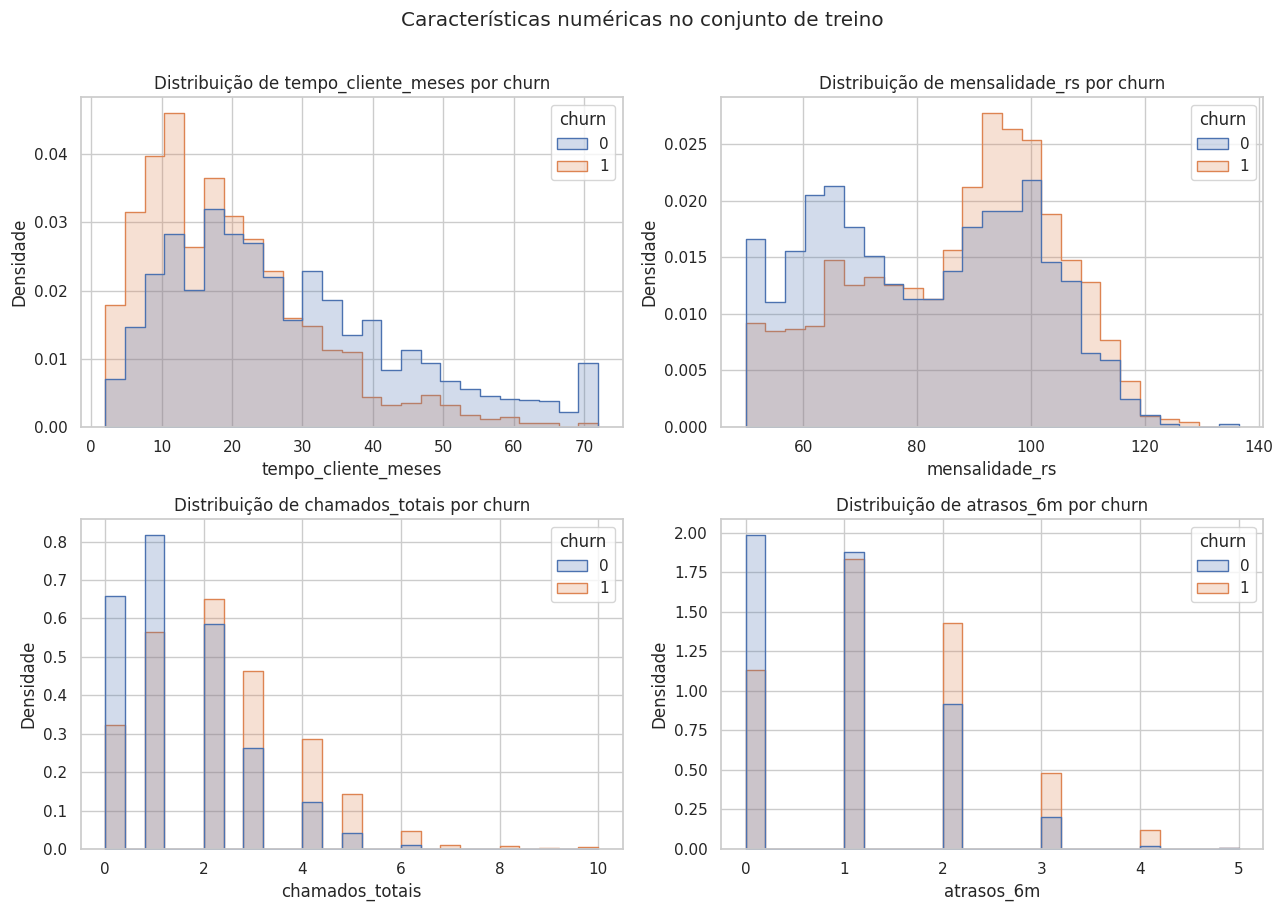

In [8]:
# Grade 2x2: um gráfico para cada variável numérica.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna in zip(axes.flat, NUMERICAS):
    sns.histplot(
        data=treino, x=coluna, hue=ALVO,   # uma cor por classe de churn
        bins=25,                           # número de barras
        stat="density",                    # eixo y em densidade, não em contagem
        common_norm=False,                 # normaliza cada classe separadamente
        element="step", ax=ax,             # contorno em degraus, para ver as duas sobrepostas
    )
    ax.set_title(f"Distribuição de {coluna} por churn")
    ax.set_ylabel("Densidade")
plt.suptitle("Características numéricas no conjunto de treino", y=1.01)
plt.tight_layout()
plt.show()

Os histogramas confirmam e detalham o que as médias sugeriam. Em **tempo de casa**, a distribuição de quem cancelou está concentrada nos primeiros meses, enquanto a de quem ficou se estende até 72 meses; a assimetria à direita é visível nos dois grupos. Em **chamados** e **atrasos**, a classe de churn está deslocada para valores maiores. Em **mensalidade**, a diferença é mais sutil, mas a curva de churn tem mais massa nas faixas acima de R$ 85.

Um detalhe chama atenção na mensalidade: a distribuição parece ter **dois picos** (bimodal), um em torno de R\$ 65 e outro perto de R\$ 97. Essa forma geralmente indica a mistura de dois grupos diferentes. A Seção 6 mostrará que esses grupos correspondem a clientes sem e com fibra óptica.

As variáveis de contagem (`tempo_cliente_meses` e `chamados_totais`) são assimétricas à direita (coeficiente de assimetria próximo de 1). Isso não é um problema para árvores de decisão, que são insensíveis à escala e ao formato das distribuições, mas pode ser relevante para modelos baseados em distância ou lineares, para os quais uma transformação logarítmica ou o uso de
escaladores robustos pode ajudar.

### 5.2 Comparação por classe com boxplots

O boxplot resume uma distribuição em poucos elementos: a **linha central** é a mediana; a **caixa** vai do primeiro ao terceiro quartil (contém os 50% centrais dos clientes); os **bigodes** se estendem até o último ponto dentro de 1,5 × IQR a partir da caixa; e os **pontos isolados** além dos bigodes são valores atípicos por esse critério. Colocar os dois boxplots lado a lado permite comparar rapidamente posição (medianas) e dispersão (tamanho das
caixas) entre as classes.

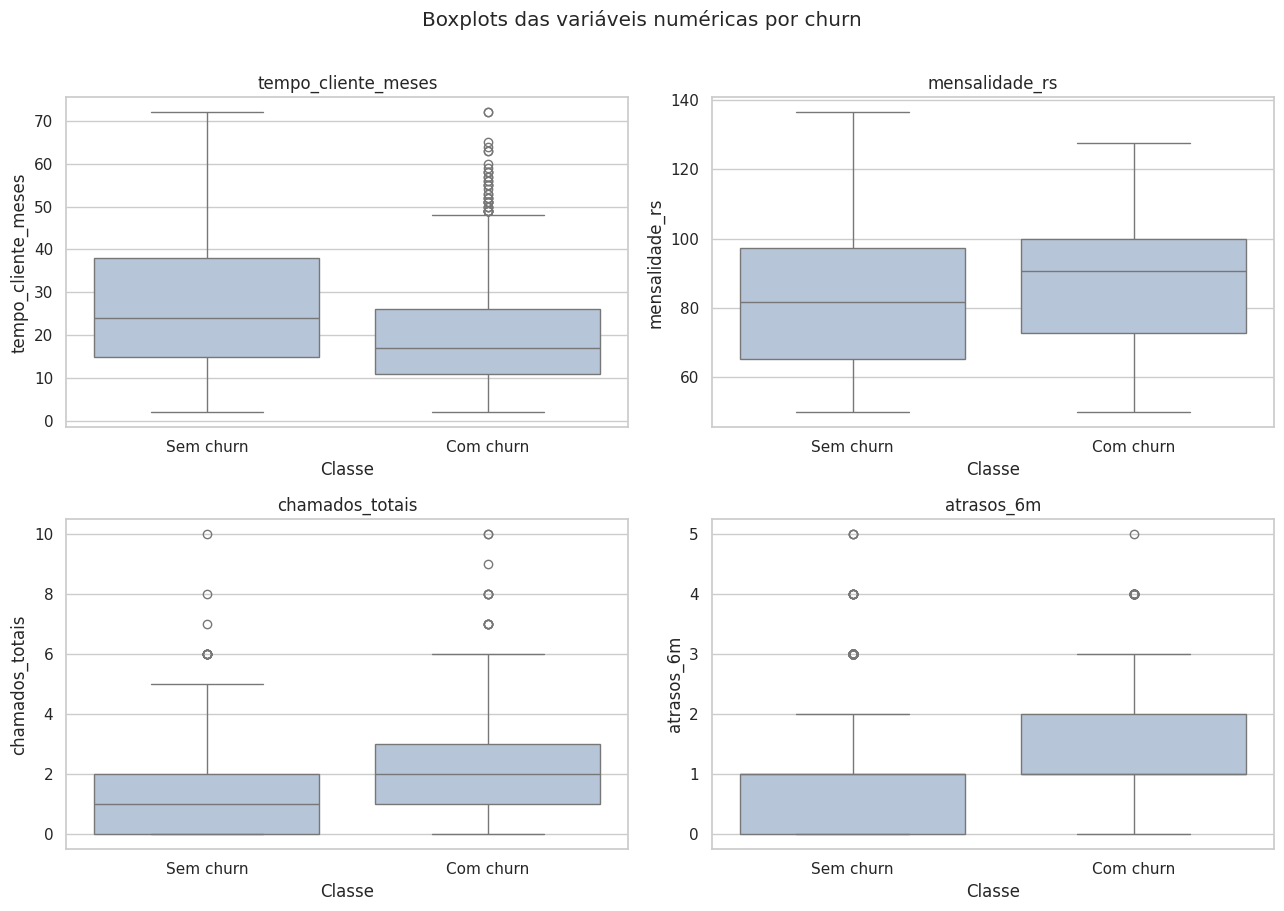

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna in zip(axes.flat, NUMERICAS):
    # Um boxplot por classe (x = churn 0/1) para a variável da vez.
    sns.boxplot(data=treino, x=ALVO, y=coluna, ax=ax, color="lightsteelblue")
    # Define as posições e os rótulos do eixo x juntos (evita aviso do matplotlib).
    ax.set_xticks([0, 1], ["Sem churn", "Com churn"])
    ax.set_xlabel("Classe")
    ax.set_title(coluna)
plt.suptitle("Boxplots das variáveis numéricas por churn", y=1.01)
plt.tight_layout()
plt.show()

Em todas as variáveis as medianas são diferentes entre as classes, mas as caixas se sobrepõem. Isso significa que **nenhuma variável sozinha separa perfeitamente** quem cancela de quem fica: há clientes antigos que cancelam e clientes com muitos chamados que permanecem. É exatamente por isso que precisamos de um modelo que combine as variáveis. A separação mais nítida está em `tempo_cliente_meses` (a caixa de churn fica bem mais baixa) e em
`chamados_totais` (a caixa de churn fica mais alta).

Os pontos acima dos bigodes em `tempo_cliente_meses` (clientes muito antigos) e em `chamados_totais` (clientes com muitos chamados) serão analisados na Seção 6.2.

### 5.3 Taxa de churn por categoria

Para variáveis categóricas e binárias, a ferramenta mais direta é a **taxa de churn por grupo**: como o alvo vale 0 ou 1, a média do alvo dentro de um grupo é a proporção de clientes daquele grupo que cancelou. Comparamos cada taxa com a taxa geral de 35,4%: grupos bem acima dela concentram risco; grupos abaixo dela são mais estáveis. A coluna `n_clientes` acompanha cada
taxa, porque uma taxa calculada sobre poucos clientes é pouco confiável. Os ausentes não entram nesta análise (o `groupby` os ignora), mas continuam no arquivo final.


Churn por tipo_contrato:


,tipo_contrato,n_clientes,taxa_churn
2,Mensal,1932,46.69%
0,Anual,819,25.27%
1,Bienal,715,16.50%


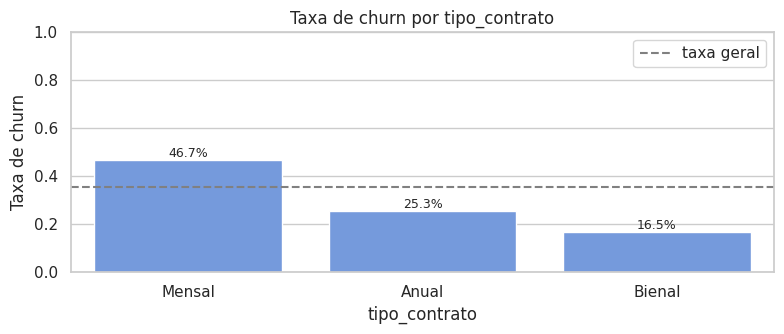


Churn por forma_pagamento:


,forma_pagamento,n_clientes,taxa_churn
2,Pix,899,36.15%
0,Boleto,1364,35.56%
1,Cartão,1206,34.58%


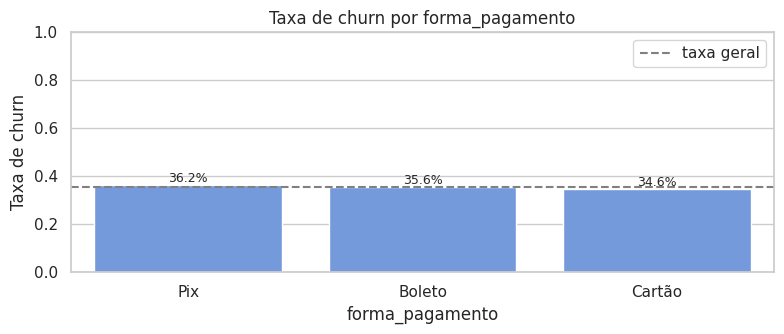


Churn por fibra_optica:


,fibra_optica,n_clientes,taxa_churn
1,1,1972,41.73%
0,0,1511,27.20%


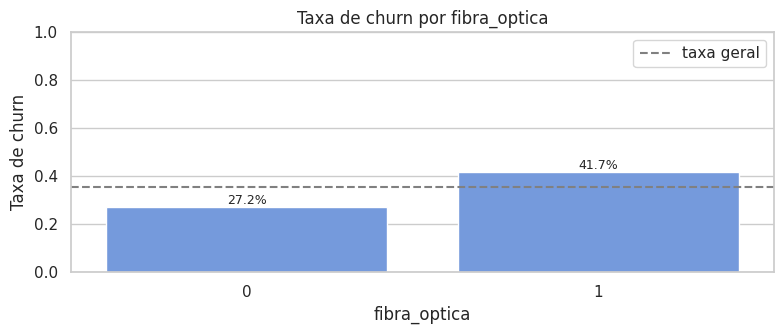


Churn por debito_automatico:


,debito_automatico,n_clientes,taxa_churn
0,0,2116,40.08%
1,1,1367,28.24%


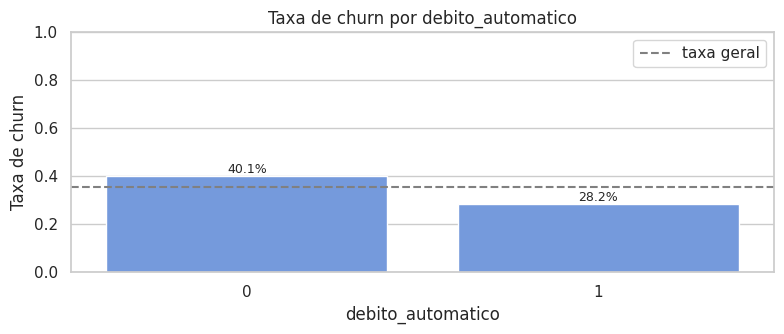

In [10]:
for coluna in CATEGORICAS + BINARIAS:
    # Para cada categoria: número de clientes (size) e taxa de churn (média do alvo 0/1).
    taxas = (
        treino.groupby(coluna)[ALVO]
        .agg(n_clientes="size", taxa_churn="mean")
        .reset_index()
        .sort_values("taxa_churn", ascending=False)
    )
    print(f"\nChurn por {coluna}:")
    display(taxas.style.format({"taxa_churn": "{:.2%}"}))

    plt.figure(figsize=(8, 3.5))
    ax = sns.barplot(data=taxas, x=coluna, y="taxa_churn", color="cornflowerblue")
    # Linha de referência: taxa geral de churn do treino.
    ax.axhline(treino[ALVO].mean(), color="gray", linestyle="--", label="taxa geral")
    ax.set(ylabel="Taxa de churn", xlabel=coluna, title=f"Taxa de churn por {coluna}", ylim=(0, 1))
    # Escreve o percentual acima de cada barra.
    for barra in ax.patches:
        ax.annotate(f"{barra.get_height():.1%}",
                    (barra.get_x() + barra.get_width()/2, barra.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.legend()
    plt.tight_layout()
    plt.show()

Os resultados separam as variáveis em dois grupos muito distintos.

**Variáveis com forte associação.** O **tipo de contrato** é o fator categórico mais marcante: 46,7% dos clientes mensais cancelaram, contra 25,3% dos anuais e apenas 16,5% dos bienais. A lógica é intuitiva, contratos longos criam um custo de saída (multa, perda de desconto), enquanto o cliente mensal pode sair a qualquer momento. Clientes com **fibra óptica** cancelam
mais (41,7% contra 27,2%), e clientes **sem débito automático** também (40,1% contra 28,2%). O débito automático reduz o atrito do pagamento e costuma estar associado a clientes mais engajados.

**Variável sem associação aparente.** A **forma de pagamento** praticamente não diferencia os clientes: Pix (36,2%), Boleto (35,6%) e Cartão (34,6%) ficam todos a no máximo um ponto da taxa geral. Pelos critérios da Aula 2, `forma_pagamento` é candidata a **variável irrelevante**. A recomendação, porém, não é descartá-la já: a Aula 2 sugere manter um modelo de referência com todas as variáveis antes de removê-las, porque uma variável sem efeito isolado pode ainda ser útil em combinação com outras.

### 5.4 Taxa de churn por faixas das variáveis numéricas

A mesma lógica de taxa por grupo pode ser aplicada às variáveis numéricas, desde que antes elas sejam divididas em faixas. Usamos **quartis** (`pd.qcut`), que criam faixas com aproximadamente o mesmo número de clientes, o que torna as taxas comparáveis. Essa visão complementa a correlação da Seção 6: ela mostra se o risco cresce de forma contínua, se há um "degrau" a partir de certo ponto ou se a relação é não linear.

Em variáveis com muitos valores repetidos (como chamados e atrasos), alguns limites de quartil coincidem; o parâmetro `duplicates="drop"` funde essas faixas, por isso algumas variáveis terminam com três faixas em vez de quatro. As faixas são apenas exploratórias e **não** são adicionadas à base.


Churn por quartis de tempo_cliente_meses:


,faixa,n_clientes,taxa_churn
0,"(1.999, 13.0]",922,50.65%
1,"(13.0, 21.0]",829,39.08%
2,"(21.0, 33.0]",892,33.52%
3,"(33.0, 72.0]",840,17.14%


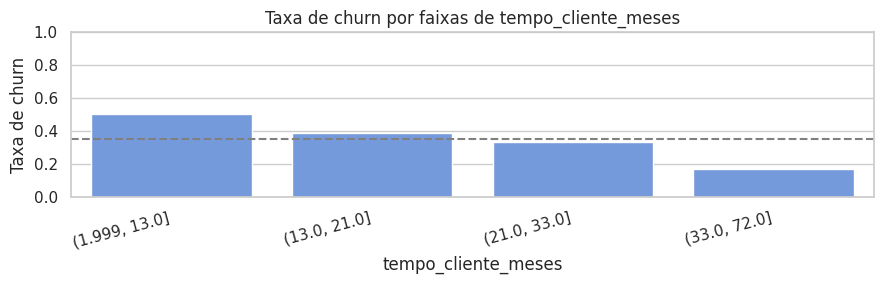


Churn por quartis de mensalidade_rs:


,faixa,n_clientes,taxa_churn
0,"(49.899, 67.14]",849,24.15%
1,"(67.14, 86.04]",846,33.92%
2,"(86.04, 98.42]",847,41.20%
3,"(98.42, 136.42]",847,41.91%


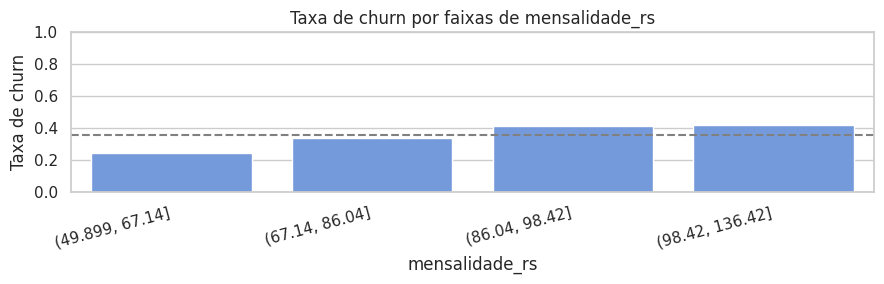


Churn por quartis de chamados_totais:


,faixa,n_clientes,taxa_churn
0,"(-0.001, 1.0]",1765,24.82%
1,"(1.0, 2.5]",847,37.90%
2,"(2.5, 10.0]",871,54.54%


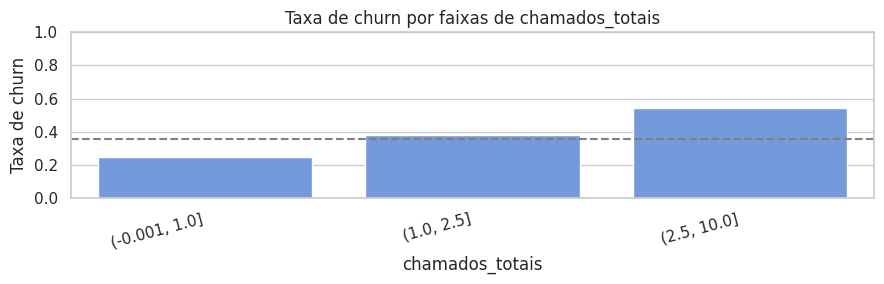


Churn por quartis de atrasos_6m:


,faixa,n_clientes,taxa_churn
0,"(-0.001, 1.0]",2445,29.78%
1,"(1.0, 2.0]",758,46.31%
2,"(2.0, 5.0]",249,59.44%


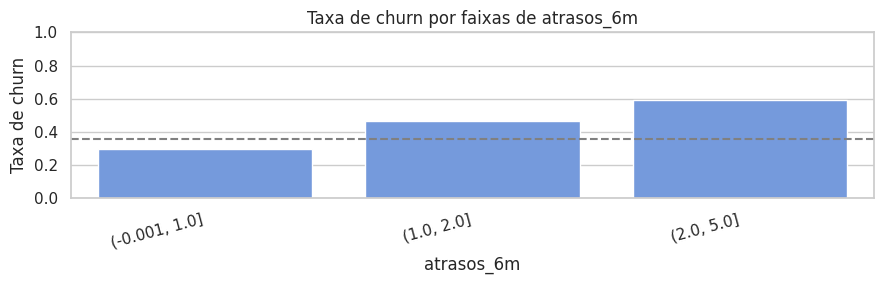

In [11]:
for coluna in NUMERICAS:
    serie = treino[coluna]
    try:
        # qcut divide em 4 faixas com quantidades parecidas de clientes (quartis).
        faixas = pd.qcut(serie, q=4, duplicates="drop")
    except ValueError:
        print(f"Não foi possível criar faixas para {coluna} (valores insuficientes).")
        continue
    agrupado = (
        treino.assign(faixa=faixas)                   # adiciona a faixa temporariamente
        .groupby("faixa", observed=True)[ALVO]        # observed=True: só faixas existentes
        .agg(n_clientes="size", taxa_churn="mean")
        .reset_index()
    )
    if agrupado.empty:
        continue
    agrupado["faixa"] = agrupado["faixa"].astype(str)  # intervalo -> texto, para o eixo x
    print(f"\nChurn por quartis de {coluna}:")
    display(agrupado.style.format({"taxa_churn": "{:.2%}"}))

    plt.figure(figsize=(9, 3))
    sns.barplot(data=agrupado, x="faixa", y="taxa_churn", color="cornflowerblue")
    plt.axhline(treino[ALVO].mean(), color="gray", linestyle="--")   # taxa geral
    plt.title(f"Taxa de churn por faixas de {coluna}")
    plt.ylabel("Taxa de churn")
    plt.xlabel(coluna)
    plt.xticks(rotation=15, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

As faixas tornam as relações muito mais legíveis do que as médias:

- **Tempo de casa** tem a relação mais forte e mais regular, sempre decrescente: 50,7% de churn até 13 meses, 39,1% entre 14 e 21, 33,5% entre 22 e 33 e apenas 17,1% acima de 33 meses. O risco do cliente mais novo é **três vezes** o do mais antigo.
- **Chamados** cresce de forma consistente: 24,8% para até 1 chamado, 37,9% para 2 e 54,5% para 3 ou mais.
- **Atrasos** também: 29,8% para até 1 atraso, 46,3% para 2 e 59,4% para 3 a 5.
- **Mensalidade** cresce até cerca de R$ 86 e depois se estabiliza (24,1% → 33,9% → 41,2% → 41,9%). Essa estabilização é um sinal de relação **não linear**, que uma correlação linear captaria apenas parcialmente e que uma árvore de decisão consegue representar naturalmente.

## 6. Relações entre variáveis e valores atípicos

### 6.1 Correlação

O **coeficiente de correlação de Pearson** (r) mede a força da associação **linear** entre duas variáveis. Ele varia de −1 a +1: valores próximos de +1 indicam que as duas crescem juntas; próximos de −1, que uma cresce enquanto a outra diminui; próximos de 0, que não há relação linear. Como referência prática, |r| abaixo de 0,1 costuma ser considerado desprezível, entre
0,1 e 0,3 fraco, entre 0,3 e 0,5 moderado e acima de 0,5 forte.

Calculamos a correlação incluindo as variáveis binárias e o próprio alvo. Quando uma das variáveis é binária, o Pearson equivale à **correlação ponto-bisserial**, e quando ambas são binárias, ao **coeficiente phi**; as duas são formas legítimas de medir associação nesses casos.

A matriz serve a dois propósitos diferentes:

1. **Relação com o alvo** (última linha/coluna): indica quais variáveis têm associação linear com o churn.
2. **Relação entre preditores** (restante da matriz): identifica **variáveis redundantes**. Quando dois preditores são fortemente correlacionados, eles carregam praticamente a mesma informação. Isso causa **multicolinearidade** em modelos lineares (coeficientes instáveis e difíceis de interpretar) e, em árvores, faz a importância se dividir de forma arbitrária entre as duas variáveis.

Duas cautelas: correlação **não implica causalidade**, e uma correlação baixa **não** significa ausência de relação, apenas ausência de relação **linear** (como vimos na mensalidade, que estabiliza a partir de certa faixa).

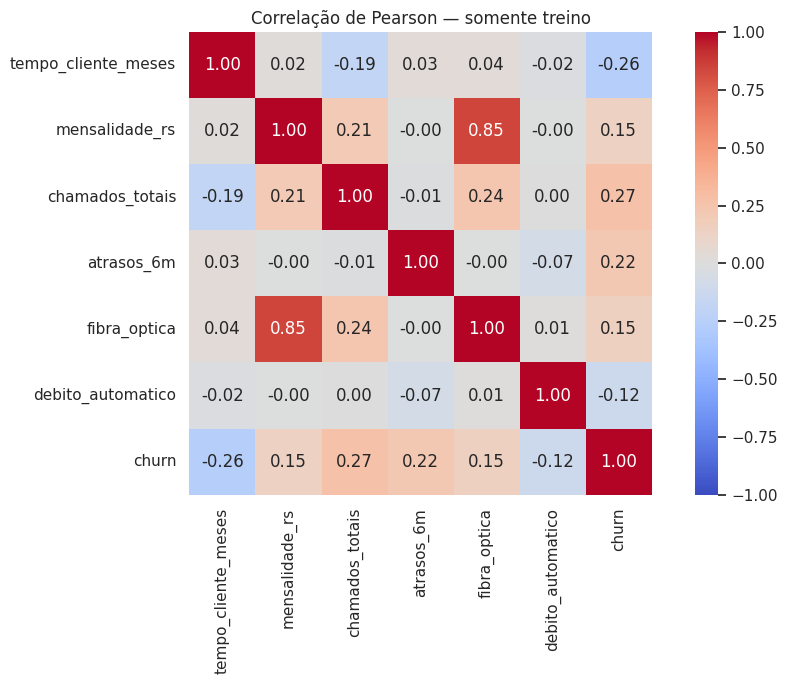

Correlação com churn (ordenada):


,correlacao_com_churn
chamados_totais,0.268340
atrasos_6m,0.222170
fibra_optica,0.150595
mensalidade_rs,0.147286
debito_automatico,-0.120862
tempo_cliente_meses,-0.260951



Pares de preditores com |r| >= 0,5:


,,r
mensalidade_rs,fibra_optica,0.85


Mensalidade média por fibra óptica:


,mean,median
fibra_optica,,
0,65.71,65.44
1,97.06,97.03


In [12]:
# Variáveis incluídas: numéricas, binárias e o alvo (as categóricas de texto ficam de fora,
# pois a correlação de Pearson exige números).
colunas_corr = NUMERICAS + BINARIAS + [ALVO]
correlacoes = treino[colunas_corr].corr(method="pearson")   # ausentes são ignorados par a par

plt.figure(figsize=(10, 7))
# Mapa de calor: annot escreve os valores; cmap divergente (azul negativo, vermelho positivo)
# centrado em 0; vmin/vmax fixam a escala em [-1, 1] para não exagerar correlações fracas.
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Correlação de Pearson — somente treino")
plt.tight_layout()
plt.show()

# Ranking das correlações com o churn (removendo a correlação do alvo com ele mesmo).
print("Correlação com churn (ordenada):")
display(correlacoes[ALVO].drop(ALVO).sort_values(ascending=False).rename("correlacao_com_churn").to_frame())

# Pares de preditores com correlação forte (|r| >= 0,5), candidatos a redundância.
# np.triu(..., k=1) mantém só o triângulo acima da diagonal, para não repetir pares.
preditores = correlacoes.drop(index=ALVO, columns=ALVO)
triangulo = preditores.where(np.triu(np.ones(preditores.shape, dtype=bool), k=1))
pares_fortes = triangulo.stack().rename("r").to_frame()
pares_fortes = pares_fortes[pares_fortes["r"].abs() >= 0.5]
print("\nPares de preditores com |r| >= 0,5:")
display(pares_fortes.round(2))

# Confirmação do achado: mensalidade média por presença de fibra óptica.
print("Mensalidade média por fibra óptica:")
display(treino.groupby("fibra_optica")["mensalidade_rs"].agg(["mean", "median"]).round(2))

**Associação com o churn.** As correlações com o alvo estão todas na faixa fraca a moderada, o que é normal em problemas de comportamento humano, em que nenhum fator isolado decide. A ordem confirma a análise por faixas: `chamados_totais` (+0,27) e `tempo_cliente_meses` (−0,26) lideram, seguidas de `atrasos_6m` (+0,22), `fibra_optica` (+0,15), `mensalidade_rs` (+0,15) e
`debito_automatico` (−0,12). Os sinais coincidem com tudo o que foi visto: mais chamados, mais atrasos e mensalidade mais alta aumentam o risco; mais tempo de casa e débito automático o reduzem. O tipo de contrato, que não entra na matriz por ser texto, também mostrou associação forte na Seção 5.3.

**Redundância entre preditores.** A matriz revela um achado importante: **`fibra_optica` e `mensalidade_rs` têm correlação de 0,85**. Clientes com fibra pagam em média R\$ 97,1, contra R\$ 65,7 dos clientes sem fibra, o que explica a distribuição bimodal da mensalidade vista na Seção 5.1. Na prática, saber se o cliente tem fibra já diz muito sobre quanto ele paga. Os demais
pares são fracos (o maior é chamados × fibra, com 0,24), então não há outros problemas de redundância.

Esse achado tem três consequências para o notebook 03:

1. Em **modelos lineares** (como a regressão logística), as duas variáveis juntas podem gerar coeficientes instáveis; vale testar o modelo com e sem uma delas.
2. Na **interpretação da importância** das variáveis em árvores, a importância pode se dividir entre as duas de forma arbitrária, e é preciso ler as duas em conjunto.
3. Na **imputação da mensalidade**, `fibra_optica` é uma ótima variável auxiliar: imputar pela mediana **dentro de cada grupo de fibra** (ou com KNNImputer usando fibra como vizinhança) será muito mais preciso do que usar uma mediana global, que ficaria entre os dois picos e não representaria bem nenhum dos grupos.

### 6.2 Valores atípicos (outliers)

Um **outlier** é um valor que se afasta muito do padrão do restante dos dados. O critério mais usado para sinalizá-los é o do **intervalo interquartil (IQR)**, o mesmo que define os bigodes do boxplot: é considerado atípico todo valor abaixo de `Q1 − 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR`. O critério é robusto porque se baseia em quartis, que não são distorcidos pelos
próprios extremos (ao contrário de regras baseadas em média e desvio padrão).

É fundamental distinguir dois tipos de valor atípico. Um **erro** é um valor impossível ou corrompido, como os sentinelas −85 e 9.999 tratados no Relatório 01 — e deve ser corrigido. Um **valor extremo legítimo** é raro, mas real, e frequentemente é justamente o caso mais informativo. Por isso o critério IQR aqui serve apenas para **sinalizar**; nenhum registro é removido automaticamente. Também medimos a taxa de churn entre os clientes sinalizados, para saber se eles carregam informação relevante.

In [13]:
resultado_outliers = []
for coluna in NUMERICAS:
    serie = treino[coluna].dropna()                       # o critério ignora ausentes
    q1, q3 = serie.quantile([0.25, 0.75])                 # primeiro e terceiro quartis
    iqr = q3 - q1                                         # amplitude da metade central
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    # Máscara dos valores fora dos limites.
    fora = (serie < limite_inf) | (serie > limite_sup)
    qtd = int(fora.sum())
    resultado_outliers.append({
        "variavel": coluna,
        "limite_inferior": limite_inf,
        "limite_superior": limite_sup,
        "possiveis_outliers": qtd,
        "percentual_dos_validos": 100 * qtd / len(serie) if len(serie) else np.nan,
        # Taxa de churn entre os sinalizados (índice alinha a máscara com o alvo).
        "taxa_churn_outliers": treino.loc[fora[fora].index, ALVO].mean() if qtd else np.nan,
    })
display(pd.DataFrame(resultado_outliers).round(2))

,variavel,limite_inferior,limite_superior,possiveis_outliers,percentual_dos_validos,taxa_churn_outliers
0,tempo_cliente_meses,-17.00,63.00,101,2.90,0.04
1,mensalidade_rs,20.22,145.34,0,0.00,NaN
2,chamados_totais,-1.25,4.75,154,4.42,0.68
3,atrasos_6m,-3.00,5.00,0,0.00,NaN


`mensalidade_rs` e `atrasos_6m` não têm nenhum valor atípico. Esse resultado é, em si, uma confirmação do Relatório 01: antes da conversão dos sentinelas, a mensalidade teria valores de −85 e 9.999 sinalizados aqui.

As outras duas variáveis têm valores sinalizados, mas **todos são legítimos**:

- **`tempo_cliente_meses`**: 101 clientes (2,9%) com mais de 63 meses de casa. São simplesmente os clientes mais antigos da operadora — e a taxa de churn entre eles é de apenas 4,0%. Eles representam o extremo de baixo risco.
- **`chamados_totais`**: 154 clientes (4,4%) com 5 ou mais chamados. A taxa de churn entre eles é de 68,2%, quase o dobro da média. Eles são o extremo de alto risco.

Removê-los seria um erro grave: o modelo perderia justamente os exemplos mais claros de cada classe. A decisão é **manter todos os registros**. Se o notebook 03 usar modelos sensíveis a escala, um escalonamento robusto (baseado em mediana e IQR) ou uma transformação logarítmica reduz a influência desses valores sem descartá-los.

## 7. Exportação da base particionada

O arquivo gerado mantém **todas as colunas e todos os valores ausentes** da base limpa, acrescentando apenas a coluna `split`. Nenhuma transformação descoberta na EDA é aplicada aqui: este notebook observa e recomenda; quem transforma é o notebook 03, ajustando tudo apenas nas linhas marcadas como `treino`. Após salvar, o arquivo é relido e verificado.

In [14]:
# Cria a pasta de saída, se necessário, e salva sem o índice numérico do pandas.
BASE_PARTICIONADA.parent.mkdir(parents=True, exist_ok=True)
base_particionada.to_csv(BASE_PARTICIONADA, index=False, encoding="utf-8")

# Validação da exportação: relê o arquivo e confere que nada se perdeu na gravação.
conferir = pd.read_csv(BASE_PARTICIONADA)
assert conferir.shape == base_particionada.shape                      # mesmas dimensões
assert conferir[ID].is_unique                                         # chave única
assert set(conferir[COLUNA_PARTICAO]) == {"treino", "teste"}          # só os dois rótulos
assert conferir[COLUNA_PARTICAO].value_counts().to_dict() == {        # mesmos tamanhos
    "treino": len(treino), "teste": len(teste),
}

print(f"Arquivo gerado: {BASE_PARTICIONADA}")
print(f"Dimensão: {conferir.shape[0]} linhas × {conferir.shape[1]} colunas")

Arquivo gerado: /content/previsao_de_evasao_de_clientes/data/processed/base_particionada.csv
Dimensão: 4976 linhas × 11 colunas


## 8. Conclusão

Este relatório estabeleceu o protocolo experimental do projeto e construiu, a partir apenas do
conjunto de treino, um entendimento detalhado de como cada variável se relaciona com a evasão.

A **divisão holdout estratificada** separou 3.483 clientes para treino e 1.493 para teste,
preservando exatamente a taxa de churn de 35,4% e sem nenhum cliente nos dois conjuntos. Com a
semente fixa, essa partição é reprodutível e será a mesma em todas as etapas seguintes.

A **análise exploratória** desenhou um perfil coerente do cliente em risco: está há pouco tempo
na operadora, tem contrato mensal, aciona o suporte com frequência, acumula atrasos de pagamento,
tem fibra óptica e não usa débito automático. Tempo de casa e chamados são os sinais numéricos
mais fortes, e o tipo de contrato é o sinal categórico mais forte. A forma de pagamento, ao
contrário, não mostrou associação com o churn. A análise de correlação revelou que fibra óptica e
mensalidade carregam boa parte da mesma informação, e a análise de outliers mostrou que os
valores extremos restantes são clientes reais e informativos.

### Síntese dos achados e recomendações para o notebook 03

| Achado | Evidência | Recomendação |
| --- | --- | --- |
| Ausências pequenas em 4 colunas | 0,4% a 2,7% no treino | Imputação simples: mediana nas numéricas, moda nas categóricas, ajustada só no treino |
| Possível sinal na falta de mensalidade | 40,4% vs. 35,3% de churn | Criar o indicador `mensalidade_ausente` |
| Mensalidade bimodal e ligada à fibra | r = 0,85; R$ 97,1 vs. R$ 65,7 | Imputar a mensalidade por grupo de fibra (ou KNNImputer) |
| Redundância fibra × mensalidade | r = 0,85 | Em modelos lineares, testar com e sem uma das duas; interpretar importâncias em conjunto |
| `forma_pagamento` sem associação | taxas entre 34,6% e 36,2% | Candidata a remoção; comparar com um modelo de referência com todas as variáveis |
| Assimetria em tempo de casa e chamados | assimetria ≈ 1 | Para modelos sensíveis a escala, considerar log ou escalonamento robusto |
| Outliers legítimos | 4,0% e 68,2% de churn | Manter todos os registros |
| Relação não linear da mensalidade | taxa estabiliza acima de R$ 86 | Árvores de decisão capturam isso naturalmente |
| Classe positiva minoritária (35,4%) | partição estratificada | Usar validação cruzada estratificada; priorizar recall e F1 em vez de acurácia |

---
### Anexo — baixar o arquivo gerado (Colab)

Ao rodar no Colab, a célula abaixo baixa a base particionada; localmente, apenas informa onde o
arquivo foi salvo.

In [15]:
try:
    from google.colab import files
    files.download(str(BASE_PARTICIONADA))
except ImportError:
    print(f"Execução local: CSV disponível em {BASE_PARTICIONADA}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>